# ENA_2025_Modulo_14


## 1. Objetivo

Exploramos las variables de Inocuidad de la ENA 2025 mediante tablas, gráficos y comparaciones territoriales, considerando las respuestas registradas en el módulo 14.

## 2. Lectura

### 2.1. Importación de librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### 2.2. Lectura de datos y diccionario

Leemos el archivo Parquet del módulo 14 y su diccionario de variables.

In [2]:
# Módulo 14
df_inocuidad = pd.read_parquet("../data/raw/2025/14_CAP600.parquet")

# Diccionario del módulo 14
df_diccionario_14 = pd.read_excel("../data/raw/excel/DICC_ENA_2025.xlsx", sheet_name="14_CAP600")

### 3.1. Primeras filas y dimensiones

Observamos los primeros registros y las dimensiones del módulo 14.

In [3]:
display(df_inocuidad.head())
print("\nFilas y columnas:", df_inocuidad.shape)

,ANIO,CCDD,NOMBREDD,CCPP,NOMBREPV,CCDI,NOMBREDI,NSEGM,ID_PROD,UA,...,P607,P608,P609,P610_1,P610_2,P610_3,P610_4,P610_5,P610_6,OMICAP600
0,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,1,1,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,2,2,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
2,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,3,3,...,2.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
3,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30001,4,4,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
4,2025,1.0,AMAZONAS,1.0,CHACHAPOYAS,1.0,CHACHAPOYAS,30002,1,1,...,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,



Filas y columnas: (40020, 61)


### 3.2. Columnas, tipos, nulos y textos vacíos

Revisamos los nombres de las columnas, sus tipos de datos y valores nulos. También los valores de `OMICAP600` para identificar posibles textos vacíos.

In [4]:
print("Columnas:", df_inocuidad.columns.tolist())
print("\n ")

# Tipos y valores no nulos
df_inocuidad.info(verbose=True, show_counts=True)

Columnas: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7', 'P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9', 'P603', 'P604', 'P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6', 'P605A', 'P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7', 'P607', 'P608', 'P609', 'P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6', 'OMICAP600']

 
<class 'pandas.DataFrame'>
RangeIndex: 40020 entries, 0 to 40019
Data columns (total 61 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ANIO              40020 non-null  int64  
 1   CCDD              38449 non-null  float64
 2   NOMBREDD          38449 non-null  str    
 3   CCPP              38449 non-null  float64


In [5]:
# Valores nulos por columna
display(df_inocuidad.isna().sum().to_frame("Nulos"))

,Nulos
ANIO,0
CCDD,1571
NOMBREDD,1571
CCPP,1571
NOMBREPV,1571
...,...
P610_3,39385
P610_4,39385
P610_5,39385
P610_6,39385


In [6]:
# Frecuencias de OMICAP600
display(df_inocuidad["OMICAP600"].value_counts(dropna=False))

OMICAP600
    40020
Name: count, dtype: int64

In [7]:
# Textos vacíos o espacios en OMICAP600
textos_vacios = df_inocuidad["OMICAP600"].fillna("").astype(str).str.strip().eq("")

print("Textos vacíos u espacios:", (textos_vacios & df_inocuidad["OMICAP600"].notna()).sum())

Textos vacíos u espacios: 40020


### 4.1. Identificación y selección de la llave

El proyecto establece una llave compuesta de siete campos para relacionar los módulos de la ENA. Verificamos cuáles están disponibles en el módulo 14 y revisamos la diferencia entre `CLUSTER` y `NSEGM`.

In [8]:
# Llave establecida en el proyecto
llave_oficial = ["ANIO", "CCDD", "CCPP", "CCDI", "CLUSTER", "ID_PROD", "UA"]

# Identificadores disponibles en el módulo
print("Columnas del módulo:", df_inocuidad.columns.tolist())

# Llave oficial vs las columnas del módulo
print("\nCampos de la llave presentes:", [col for col in llave_oficial if col in df_inocuidad.columns])
print("Campos de la llave ausentes:", [col for col in llave_oficial if col not in df_inocuidad.columns])

Columnas del módulo: ['ANIO', 'CCDD', 'NOMBREDD', 'CCPP', 'NOMBREPV', 'CCDI', 'NOMBREDI', 'NSEGM', 'ID_PROD', 'UA', 'RESFIN', 'REGION', 'ESTRATO', 'FACTOR_PRODUCTOR', 'CODIGO', 'P101A', 'P142_1', 'P142_2', 'P142_3', 'P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7', 'P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9', 'P603', 'P604', 'P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6', 'P605A', 'P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7', 'P607', 'P608', 'P609', 'P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6', 'OMICAP600']

Campos de la llave presentes: ['ANIO', 'CCDD', 'CCPP', 'CCDI', 'ID_PROD', 'UA']
Campos de la llave ausentes: ['CLUSTER']


In [9]:
# Llave candidata
llave_14 = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "ID_PROD", "UA"]

print("Llave candidata:", llave_14)
print("Campos disponibles:", all(col in df_inocuidad.columns for col in llave_14))

Llave candidata: ['ANIO', 'CCDD', 'CCPP', 'CCDI', 'NSEGM', 'ID_PROD', 'UA']
Campos disponibles: True


### 4.2. Valores faltantes y repeticiones

Revisamos los identificadores incompletos y verificamos si existen combinaciones repetidas de la llave candidata y de la identificación de UA.

In [10]:
# Valores nulos por identificador
print(df_inocuidad[llave_14].isna().sum())

# Registros con algún identificador faltante
print("\nRegistros incompletos:", df_inocuidad[llave_14].isna().any(axis=1).sum())

ANIO          0
CCDD       1571
CCPP       1571
CCDI       1571
NSEGM         0
ID_PROD       0
UA            0
dtype: int64

Registros incompletos: 1571


In [11]:
# Registros con todos los identificadores presentes
df_llave_completa = df_inocuidad.dropna(subset=llave_14)

print("Registros con llave completa:", len(df_llave_completa))
print("Combinaciones repetidas:", df_llave_completa.duplicated(subset=llave_14).sum())

Registros con llave completa: 38449
Combinaciones repetidas: 0


In [12]:
# Identificación de UA sin ID_PROD
llave_ua = ["ANIO", "CCDD", "CCPP", "CCDI", "NSEGM", "UA"]

# Comprobar combinaciones repetidas
repeticiones_ua = df_llave_completa.duplicated(subset=llave_ua, keep=False)

print("Filas con identificación de UA repetida:", repeticiones_ua.sum())

# Mostrar registros repetidos, si existen
if repeticiones_ua.any():
    display(df_llave_completa.loc[repeticiones_ua, llave_14].head(10))

Filas con identificación de UA repetida: 0


### 4.3. Delimitación de registros

Excluimos los registros sin nombre de departamento, según el criterio del proyecto. Comprobamos el año y el resultado final de la encuesta sin modificar los datos originales.

In [13]:
# Registros sin departamento
sin_departamento = df_inocuidad["NOMBREDD"].isna().sum()

# Crear un .copy .capy para próximos análisis
df_analisis = df_inocuidad[df_inocuidad["NOMBREDD"].notna()].copy()

print("Registros sin departamento:", sin_departamento)
print("Registros disponibles para análisis:", len(df_analisis))

# Verificar año y resultado final
print("\nAños:")
print(df_analisis["ANIO"].value_counts(dropna=False))

print("\nResultado final de encuesta:")
print(df_analisis["RESFIN"].value_counts(dropna=False))

Registros sin departamento: 1571
Registros disponibles para análisis: 38449

Años:
ANIO
2025    38449
Name: count, dtype: int64

Resultado final de encuesta:
RESFIN
1    38449
Name: count, dtype: int64


## 5. Reconocimiento del módulo completo
### 5.1. Lectura documental

Consultamos el diccionario completo del módulo 14 para identificar las preguntas, sus respuestas y las condiciones de aplicación.

In [14]:
columnas_diccionario = ["NOMBRE DE LA VARIABLE", "DESCRIPCIÓN DE LAS VARIABLES", "VALOR"]

# Show diccionario en grupos de 25 filas
for inicio in range(0, len(df_diccionario_14), 25):
    display(df_diccionario_14.iloc[inicio:inicio + 25][columnas_diccionario])

,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
0,ANIO,AÑO,NaN
1,CCDD,Código de Departamento,NaN
2,NOMBREDD,Nombre de Departamento,NaN
3,CCPP,Código de Provincia,NaN
4,NOMBREPV,Nombre de la Provincia,NaN
5,CCDI,Código del Distrito,NaN
6,NOMBREDI,Nombre del Distrito,NaN
7,NSEGM,NÚMERO CORRELATIVO EN SECUENCIA,NaN
8,NaN,SERPENTIN POR REGIÓN,NaN
9,ID_PROD,Identificador de la Unidad Agropecuaria,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
25,NaN,NaN,4 ¿Sociedad comercial de responsabilidad limi...
26,NaN,SU CONDICIÓN JURÍDICA COMO PRODUCTOR O EMPRESA...,6 ¿Cooperativa agraria?
27,P101A,NaN,7 ¿Sociedad anónima?
28,NaN,NaN,8 ¿Otro?
29,P142_1,"EN LOS ÚLTIMOS 12 MESES, DE…..A LA",NaN
30,NaN,EMPRESA/UD. REALIZÓ ACTIVIDAD: ¿Agrícola?,NaN
31,P142_2,"EN LOS ÚLTIMOS 12 MESES, DE…..A LA",NaN
32,NaN,EMPRESA/UD. REALIZÓ ACTIVIDAD: ¿Pecuaria?,NaN
33,NaN,"EN LOS ÚLTIMOS 12 MESES, DE…..A LA",NaN
34,P142_3,EMPRESA/UD. REALIZÓ ACTIVIDAD: NO REALIZÓ ACTI...,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
50,P602_4,¿QUÉ HACE CON LOS RESIDUOS DE SUS,NaN
51,NaN,ANIMALES DE CRIANZA? 4. Usa como abono,NaN
52,NaN,¿QUÉ HACE CON LOS RESIDUOS DE SUS,NaN
53,P602_5,ANIMALES DE CRIANZA? 5. Usa como combustible,NaN
54,P602_6,¿QUÉ HACE CON LOS RESIDUOS DE SUS,NaN
55,NaN,ANIMALES DE CRIANZA? 6. Deja en el campo,NaN
56,P602_7,¿QUÉ HACE CON LOS RESIDUOS DE SUS ANIMALES DE ...,NaN
57,NaN,¿QUÉ HACE CON LOS RESIDUOS DE SUS ANIMALES DE ...,NaN
58,P602_8,APÍCOLA,NaN
59,NaN,¿QUÉ HACE CON LOS RESIDUOS DE SUS ANIMALES DE ...,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
75,P605_6,¿QUÉ ENTIDAD DEL ESTADO LE INFORMÓ? 6. Otro,NaN
76,NaN,¿SABE UD. SOBRE LOS LÍMITES MÁXIMOS PERMISIBLE...,NaN
77,P605A,NaN,1 Sí
78,NaN,NaN,2 No
79,NaN,"¿EN QUÉ LUGAR ALMACENA, CONSERVA O GUARDA LOS ...",NaN
80,P606_1,productos primarios)? 1. En un lugar refrigerado,NaN
81,NaN,"¿EN QUÉ LUGAR ALMACENA, CONSERVA O GUARDA LOS ...",NaN
82,P606_2,productos primarios)? 2. A la intemperie,NaN
83,NaN,"¿EN QUÉ LUGAR ALMACENA, CONSERVA O GUARDA LOS ...",NaN
84,P606_3,productos primarios)? 3. En cuarto seguro y ve...,NaN


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
100,P609,NaN,2 ¿Asociación/cooperativa/comité (grupal)?
101,P610_1,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 1.,NaN
102,NaN,Buenas prácticas agrícolas (Global Gap),NaN
103,P610_2,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 2.,NaN
104,NaN,Comercio justo (Fair trade),NaN
105,P610_3,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 3.,NaN
106,NaN,TNC (Tesco Natural Choice),NaN
107,P610_4,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 4.,NaN
108,NaN,Orgánica,NaN
109,P610_5,¿CUÁL ES EL NOMBRE DE LA CERTIFICACIÓN? 5.,NaN


### 5.2. Frecuencias de todas las preguntas

Revisamos los valores registrados y sus frecuencias en todas las variables del módulo 14, incluyendo los valores nulos.

In [15]:
# Seleccionamos las variables del módulo 14
preguntas = [col for col in df_analisis.columns if col.startswith("P6")]

print("Variables encontradas:", len(preguntas))
print("\nVariables:", preguntas)

Variables encontradas: 41

Variables: ['P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7', 'P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9', 'P603', 'P604', 'P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6', 'P605A', 'P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7', 'P607', 'P608', 'P609', 'P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6']


In [16]:
# Contar las respuestas de cada variable
filas = []

for variable in preguntas:
    for valor, frecuencia in df_analisis[variable].value_counts(dropna=False).items():
        filas.append({
            "variable": variable,
            "valor_observado": valor,
            "registros": frecuencia
        })

frecuencias = pd.DataFrame(filas)
display(frecuencias)

,variable,valor_observado,registros
0,P601_1,0.0,31801
1,P601_1,1.0,6648
2,P601_2,0.0,28882
3,P601_2,1.0,9567
4,P601_3,0.0,37105
...,...,...,...
90,P610_5,NaN,38302
91,P610_5,0.0,145
92,P610_5,1.0,2
93,P610_6,NaN,38302


In [17]:
totales = frecuencias.groupby("variable")["registros"].sum()

print("Variables contabilizadas:", len(totales))
print("Registros analizados:", len(df_analisis))
print("¿Todos los conteos coinciden?:", (totales == len(df_analisis)).all())

Variables contabilizadas: 41
Registros analizados: 38449
¿Todos los conteos coinciden?: True


### 5.3. Selección justificada

Revisamos las preguntas del módulo 14 y seleccionamos cinco variables para los análisis iniciales. Consultamos sus significados y códigos antes de interpretar las respuestas.

In [18]:
# Variables seleccionadas
variables_seleccionadas = ["P603", "P604", "P605A", "P607", "P608", "P609"]

# Consultar sus descripciones en el diccionario
for variable in variables_seleccionadas:
    print("\nVariable:", variable)
    display(df_diccionario_14.loc[
        df_diccionario_14["NOMBRE DE LA VARIABLE"]==variable,
        ["NOMBRE DE LA VARIABLE", "DESCRIPCIÓN DE LAS VARIABLES", "VALOR"]
    ])


Variable: P603


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
61,P603,¿EXISTEN MINAS EN EXPLOTACIÓN CERCA A SUS CULT...,1 Sí



Variable: P604


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
64,P604,NaN,2 No



Variable: P605A


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
77,P605A,NaN,1 Sí


... (2 outputs left out)


Variable: P608


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
98,P608,NaN,2 No



Variable: P609


,NOMBRE DE LA VARIABLE,DESCRIPCIÓN DE LAS VARIABLES,VALOR
100,P609,NaN,2 ¿Asociación/cooperativa/comité (grupal)?


In [19]:
# Frecuencias
for variable in variables_seleccionadas:
    print("\nVariable:", variable)
    print(df_analisis[variable].value_counts(dropna=False))


Variable: P603
P603
2.0    35860
1.0     2589
Name: count, dtype: int64

Variable: P604
P604
2.0    36477
1.0     1972
Name: count, dtype: int64

Variable: P605A
P605A
2.0    35725
1.0     2724
Name: count, dtype: int64

Variable: P607
P607
2.0    30726
1.0     6476
NaN     1247
Name: count, dtype: int64

Variable: P608
P608
2    38302
1      147
Name: count, dtype: int64

Variable: P609
P609
NaN    38302
2.0       80
1.0       67
Name: count, dtype: int64


In [20]:
# Significados de las variables seleccionadas
significados = {
    "P603": "Minas en explotación cerca de cultivos y/o animales de crianza",
    "P604": "Alguna entidad del Estado informó sobre contaminación de alimentos",
    "P605A": "Sabe sobre límites máximos permisibles de contaminantes en alimentos de consumo humano y/o animal",
    "P607": "Sabe que los alimentos de consumo humano que produce deben estar identificados (productos primarios)",
    "P608": "Productos agropecuarios con certificación de calidad otorgada por una institución"
}

display(pd.Series(significados, name="Significado").to_frame())

,Significado
P603,Minas en explotación cerca de cultivos y/o ani...
P604,Alguna entidad del Estado informó sobre contam...
P605A,Sabe sobre límites máximos permisibles de cont...
P607,Sabe que los alimentos de consumo humano que p...
P608,Productos agropecuarios con certificación de c...


### 6.1. Preguntas con categorías 1/2

Contamos las respuestas "Sí" (1), "No" (2), los valores nulos y otros códigos de las cinco variables seleccionadas. Calculamos la disponibilidad de respuestas válidas sobre el total de registros analizados.

In [21]:
# Frecuencias
filas = []

for variable in significados:
    respuestas = df_analisis[variable]

    filas.append({
        "variable": variable,
        "si": (respuestas == 1).sum(),
        "no": (respuestas == 2).sum(),
        "nulos": respuestas.isna().sum(),
        "otros": (respuestas.notna() & ~respuestas.isin([1, 2])).sum()
    })

disponibilidad = pd.DataFrame(filas).set_index("variable")

# Respuestas válidas y porcentaje disponible
disponibilidad["validas"] = disponibilidad["si"]+disponibilidad["no"]
disponibilidad["porcentaje_disponible"] = (
    disponibilidad["validas"] / len(df_analisis)*100
).round(2)

display(disponibilidad)

,si,no,nulos,otros,validas,porcentaje_disponible
variable,,,,,,
P603,2589,35860,0,0,38449,100.00
P604,1972,36477,0,0,38449,100.00
P605A,2724,35725,0,0,38449,100.00
P607,6476,30726,1247,0,37202,96.76
P608,147,38302,0,0,38449,100.00


### 6.2. Condiciones observadas y respuestas múltiples

Revisamos las respuestas múltiples de los grupos P601, P602, P605, P606 y P610. También comprobamos la relación entre las preguntas condicionadas y la presencia de sus respuestas.

In [22]:
# Grupos de preguntas múltiples
prefijos = ["P601_", "P602_", "P605_", "P606_", "P610_"]

grupos = {}

for prefijo in prefijos:
    grupos[prefijo] = [col for col in preguntas if col.startswith(prefijo)]

# Comprobar las variables de cada grupo
for prefijo, columnas in grupos.items():
    print("\nGrupo:", prefijo)
    print("Variables:", columnas)
    print("Cantidad:", len(columnas))


Grupo: P601_
Variables: ['P601_1', 'P601_2', 'P601_3', 'P601_4', 'P601_5', 'P601_6', 'P601_7']
Cantidad: 7

Grupo: P602_
Variables: ['P602_1', 'P602_2', 'P602_3', 'P602_4', 'P602_5', 'P602_6', 'P602_7', 'P602_8', 'P602_9']
Cantidad: 9

Grupo: P605_
Variables: ['P605_1', 'P605_2', 'P605_3', 'P605_4', 'P605_5', 'P605_6']
Cantidad: 6

Grupo: P606_
Variables: ['P606_1', 'P606_2', 'P606_3', 'P606_4', 'P606_5', 'P606_6', 'P606_7']
Cantidad: 7

Grupo: P610_
Variables: ['P610_1', 'P610_2', 'P610_3', 'P610_4', 'P610_5', 'P610_6']
Cantidad: 6


In [23]:
# Revisar las respuestas de cada grupo
for prefijo, columnas in grupos.items():
    print("\nGrupo:", prefijo)

    # Cantidad de valores 1 por registro
    cantidad_unos = df_analisis[columnas].eq(1).sum(axis=1)

    print("Valores 1 por registro:")
    display(cantidad_unos.value_counts().sort_index())

    # Registros con todas las respuestas nulas
    todo_nulo = df_analisis[columnas].isna().all(axis=1)

    print("Registros con todo el grupo nulo:", todo_nulo.sum())
    print("Registros con más de un valor 1:", (cantidad_unos > 1).sum())


Grupo: P601_
Valores 1 por registro:


1    21893
2    13273
3     3008
4      263
5       12
Name: count, dtype: int64

Registros con todo el grupo nulo: 0
Registros con más de un valor 1: 16556

Grupo: P602_
Valores 1 por registro:


1    28834
2     8388
3     1179
4       44
5        3
6        1
Name: count, dtype: int64

Registros con todo el grupo nulo: 0
Registros con más de un valor 1: 9615

Grupo: P605_
Valores 1 por registro:


0    36477
1     1802
2      152
3       14
4        2
5        2
Name: count, dtype: int64

Registros con todo el grupo nulo: 36477
Registros con más de un valor 1: 170

Grupo: P606_
Valores 1 por registro:


1    24734
2    12297
3     1344
4       72
5        2
Name: count, dtype: int64

Registros con todo el grupo nulo: 0
Registros con más de un valor 1: 13715

Grupo: P610_
Valores 1 por registro:


0    38302
1      135
2        9
3        3
Name: count, dtype: int64

Registros con todo el grupo nulo: 38302
Registros con más de un valor 1: 12


In [24]:
# Información recibida y presencia de P605
print("P604 y respuestas presentes en P605:")
display(pd.crosstab(df_analisis["P604"], df_analisis[grupos["P605_"]].notna().sum(axis=1), dropna=False))

# Certificación y presencia de P609
print("\nP608 y presencia de P609:")
display(pd.crosstab(df_analisis["P608"], df_analisis["P609"].notna(), dropna=False))

# Certificación y presencia de P610
print("\nP608 y respuestas presentes en P610:")
display(pd.crosstab(df_analisis["P608"], df_analisis[grupos["P610_"]].notna().sum(axis=1), dropna=False))

# Alimentos de consumo humano y presencia de P607
print("\nP606_7 y presencia de P607:")
display(pd.crosstab(df_analisis["P606_7"], df_analisis["P607"].notna(), dropna=False))

P604 y respuestas presentes en P605:


col_0,0,6
P604,,
1.0,0,1972
2.0,36477,0



P608 y presencia de P609:


P609,False,True
P608,,
1,0,147
2,38302,0



P608 y respuestas presentes en P610:


col_0,0,6
P608,,
1,0,147
2,38302,0



P606_7 y presencia de P607:


P607,False,True
P606_7,,
0.0,0,37202
1.0,1247,0


Las tablas nos permiten identificar `patrones` de respuestas múltiples y condiciones observadas!

## 7. Análisis descriptivos

### 7.1. Información, conocimientos, entorno y certificación

Calculamos el porcentaje de respuestas «Sí» entre las respuestas válidas de las cinco preguntas seleccionadas, conservando sus frecuencias y denominadores.

In [25]:
# Resumen de las preguntas seleccionadas
resumen_inocuidad = disponibilidad[["si", "no", "validas"]].copy()

# Porcentaje de respuestas Sí
resumen_inocuidad["porcentaje_si"] = (
    resumen_inocuidad["si"] / resumen_inocuidad["validas"].replace(0, float("nan")) * 100
).round(2)

display(resumen_inocuidad)

,si,no,validas,porcentaje_si
variable,,,,
P603,2589,35860,38449,6.73
P604,1972,36477,38449,5.13
P605A,2724,35725,38449,7.08
P607,6476,30726,37202,17.41
P608,147,38302,38449,0.38


In [26]:
# Comprobar los denominadores
print("Denominadores correctos:", (
    resumen_inocuidad["si"] + resumen_inocuidad["no"] == resumen_inocuidad["validas"]
).all())

# Comprobar las preguntas
print("Preguntas analizadas:", len(resumen_inocuidad))
print("Porcentajes válidos:", resumen_inocuidad["porcentaje_si"].dropna().between(0, 100).all())

# Comprobar las respuestas válidas
display(resumen_inocuidad[["si", "no", "validas", "porcentaje_si"]])

Denominadores correctos: True
Preguntas analizadas: 5
Porcentajes válidos: True


,si,no,validas,porcentaje_si
variable,,,,
P603,2589,35860,38449,6.73
P604,1972,36477,38449,5.13
P605A,2724,35725,38449,7.08
P607,6476,30726,37202,17.41
P608,147,38302,38449,0.38


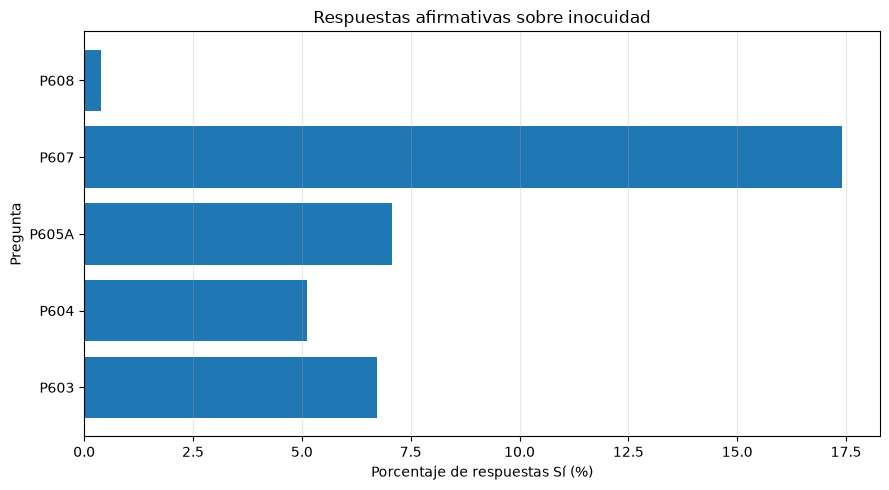

In [27]:
# Porcentaje de respuestas Sí por pregunta
plt.figure(figsize=(9, 5))

plt.barh(resumen_inocuidad.index, resumen_inocuidad["porcentaje_si"])

plt.title("Respuestas afirmativas sobre inocuidad")
plt.xlabel("Porcentaje de respuestas Sí (%)")
plt.ylabel("Pregunta")

plt.grid(axis="x", alpha=0.29)
plt.tight_layout()
plt.show()

### 7.2. Información estatal por región natural

Comparamos las respuestas sobre información recibida del Estado entre Costa, Sierra y Selva. Calculamos el porcentaje de respuestas «Sí» utilizando las respuestas válidas de cada región.

In [28]:
# Registros con región natural y respuesta válida
datos_region = df_analisis[
    df_analisis["REGION"].isin([1, 2, 3]) &
    df_analisis["P604"].isin([1, 2])
].copy()

print("Registros incluidos:", len(datos_region))
print("Registros no incluidos:", len(df_analisis) - len(datos_region))

Registros incluidos: 38449
Registros no incluidos: 0


In [29]:
# Frecuencias de información estatal por región
tabla_region = pd.crosstab(datos_region["REGION"], datos_region["P604"])

# Organizar regiones y respuestas
tabla_region = tabla_region.reindex(index=[1, 2, 3], columns=[1, 2], fill_value=0)
tabla_region.index = ["Costa", "Sierra", "Selva"]
tabla_region.columns = ["Sí", "No"]

display(tabla_region)

,Sí,No
Costa,549,8250
Sierra,1039,21399
Selva,384,6828


In [30]:
# Total de respuestas válidas por región
tabla_region["Total válido"] = tabla_region["Sí"] + tabla_region["No"]

# Porcentaje de respuestas Sí
tabla_region["Porcentaje Sí"] = (
    tabla_region["Sí"] / tabla_region["Total válido"].replace(0, float("nan")) * 100
).round(2)

display(tabla_region)

,Sí,No,Total válido,Porcentaje Sí
Costa,549,8250,8799,6.24
Sierra,1039,21399,22438,4.63
Selva,384,6828,7212,5.32


In [31]:
# Comprobar los totales
print("Registros incluidos:", len(datos_region))
print("Respuestas contabilizadas:", tabla_region["Total válido"].sum())
print("Totales coinciden:", len(datos_region) == tabla_region["Total válido"].sum())

# Comprobar los porcentajes
print("Porcentajes válidos:", tabla_region["Porcentaje Sí"].dropna().between(0, 100).all())

# Comprobar los códigos de región
print("Regiones encontradas:", sorted(datos_region["REGION"].dropna().unique().tolist()))

Registros incluidos: 38449
Respuestas contabilizadas: 38449
Totales coinciden: True
Porcentajes válidos: True
Regiones encontradas: [1, 2, 3]


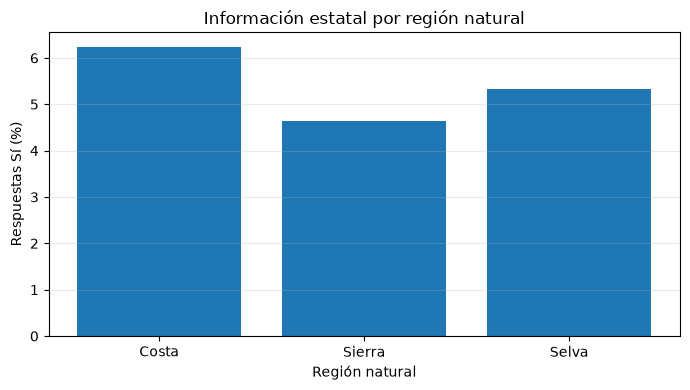

In [32]:
# Porcentaje de información estatal por región
plt.figure(figsize=(7, 4))

plt.bar(tabla_region.index, tabla_region["Porcentaje Sí"])

plt.title("Información estatal por región natural")
plt.xlabel("Región natural")
plt.ylabel("Respuestas Sí (%)")

plt.grid(axis="y", alpha=0.27)
plt.tight_layout()
plt.show()

### 7.3. Información estatal por departamento

Comparamos las respuestas sobre información recibida del Estado entre departamentos. Calculamos el porcentaje de respuestas «Sí» utilizando las respuestas válidas de cada departamento.

In [33]:
# Frecuencias de información estatal por departamento
tabla_departamento = pd.crosstab(datos_region["NOMBREDD"], datos_region["P604"])

# Organizar las respuestas
tabla_departamento = tabla_departamento.reindex(columns=[1, 2], fill_value=0)
tabla_departamento.columns = ["Sí", "No"]

display(tabla_departamento)

,Sí,No
NOMBREDD,,
AMAZONAS,91,1572
ANCASH,93,2930
APURIMAC,128,1653
AREQUIPA,91,2236
AYACUCHO,173,2819
CAJAMARCA,118,2690
CALLAO,0,4
CUSCO,63,2173
HUANCAVELICA,77,1200


In [34]:
# Total de respuestas válidas por departamento
tabla_departamento["Total válido"] = tabla_departamento["Sí"] + tabla_departamento["No"]

# Porcentaje de respuestas Sí
tabla_departamento["Porcentaje Sí"] = (
    tabla_departamento["Sí"] / tabla_departamento["Total válido"] * 100
).round(2)

# Ordenar por porcentaje
tabla_departamento = tabla_departamento.sort_values("Porcentaje Sí", ascending=False)

display(tabla_departamento)

,Sí,No,Total válido,Porcentaje Sí
NOMBREDD,,,,
TACNA,155,1003,1158,13.39
UCAYALI,96,731,827,11.61
LAMBAYEQUE,82,701,783,10.47
ICA,81,860,941,8.61
APURIMAC,128,1653,1781,7.19
SAN MARTIN,86,1203,1289,6.67
JUNIN,106,1597,1703,6.22
HUANCAVELICA,77,1200,1277,6.03
MOQUEGUA,60,957,1017,5.90


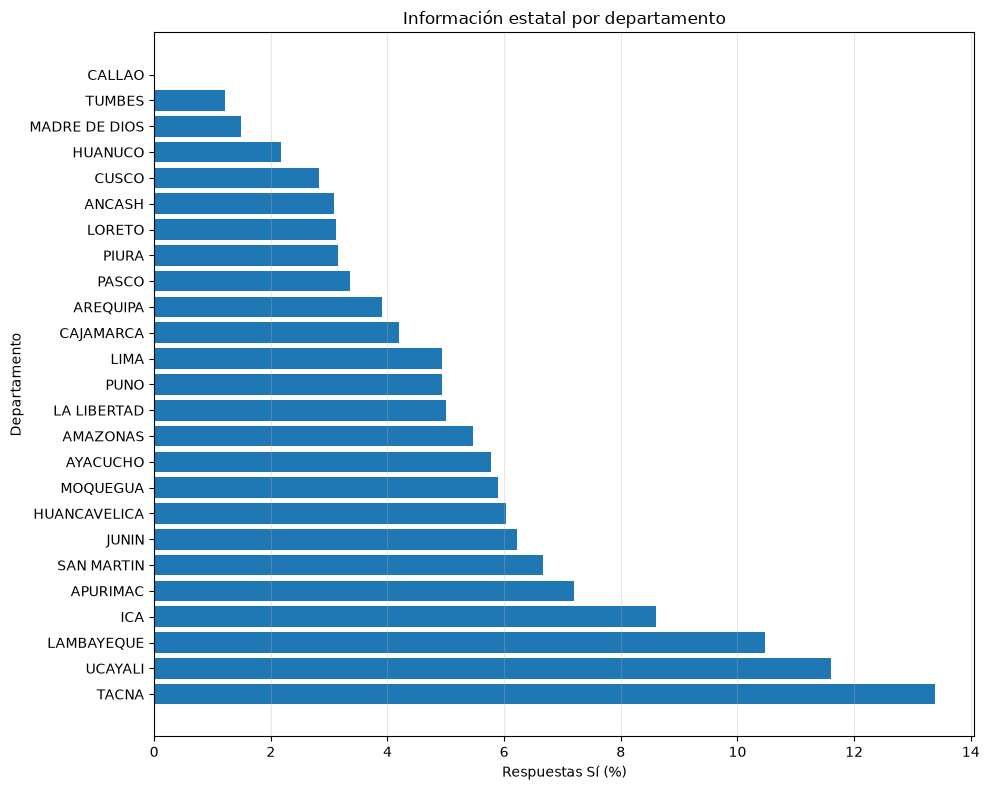

In [35]:
# Porcentaje de información estatal por departamento
plt.figure(figsize=(10, 8))

plt.barh(tabla_departamento.index, tabla_departamento["Porcentaje Sí"])

plt.title("Información estatal por departamento")
plt.xlabel("Respuestas Sí (%)")
plt.ylabel("Departamento")

plt.grid(axis="x", alpha=0.3131)
plt.tight_layout()
plt.show()

### 7.4. Información recibida y conocimiento declarado

Comparamos el conocimiento declarado de los límites máximos permisibles (`P605A`) según la información estatal recibida (`P604`). Calculamos los porcentajes utilizando las respuestas válidas de cada grupo.

In [36]:
# Registros con respuestas válidas en ambas preguntas
datos_conocimiento = df_analisis[
    df_analisis["P604"].isin([1, 2]) &
    df_analisis["P605A"].isin([1, 2])
].copy()

print("Registros incluidos:", len(datos_conocimiento))
print("Registros no incluidos:", len(df_analisis) - len(datos_conocimiento))

Registros incluidos: 38449
Registros no incluidos: 0


In [37]:
# Frecuencias de conocimiento según información recibida
tabla_conocimiento = pd.crosstab(datos_conocimiento["P604"], datos_conocimiento["P605A"])

# Organizar las respuestas
tabla_conocimiento = tabla_conocimiento.reindex(index=[1, 2], columns=[1, 2], fill_value=0)
tabla_conocimiento.index = ["Recibió información", "No recibió información"]
tabla_conocimiento.columns = ["Conoce límites", "No conoce límites"]

display(tabla_conocimiento)

,Conoce límites,No conoce límites
Recibió información,610,1362
No recibió información,2114,34363


In [38]:
# Total de respuestas válidas por grupo
tabla_conocimiento["Total válido"] = tabla_conocimiento["Conoce límites"] + tabla_conocimiento["No conoce límites"]

# Porcentaje de respuestas Sí a P605A
tabla_conocimiento["Porcentaje Sí"] = (
    tabla_conocimiento["Conoce límites"] / tabla_conocimiento["Total válido"].replace(0, float("nan")) * 100
).round(2)

display(tabla_conocimiento)

,Conoce límites,No conoce límites,Total válido,Porcentaje Sí
Recibió información,610,1362,1972,30.93
No recibió información,2114,34363,36477,5.80


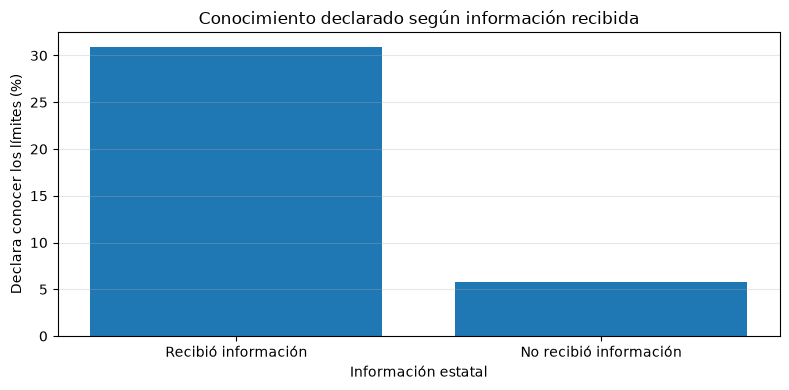

In [39]:
# Porcentaje de conocimiento según información estatal
plt.figure(figsize=(8, 4))

plt.bar(tabla_conocimiento.index, tabla_conocimiento["Porcentaje Sí"])

plt.title("Conocimiento declarado según información recibida")
plt.xlabel("Información estatal")
plt.ylabel("Declara conocer los límites (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Entre los registros que declararon recibir información estatal, el 30,93 % también declaró conocer los límites máximos permisibles.

Entre quienes no recibieron información, el porcentaje fue de 5,80 %.

### 7.5. Modalidad de certificación

Analizamos las modalidades de certificación registradas en `P609` entre quienes respondieron «Sí» a `P608`. Calculamos sus frecuencias y porcentajes utilizando las respuestas válidas.

In [40]:
# Registros que declaran certificación
datos_certificacion = df_analisis[df_analisis["P608"] == 1].copy()

print("Registros con certificación:", len(datos_certificacion))
print("\nRespuestas de P609:")
print(datos_certificacion["P609"].value_counts(dropna=False))

Registros con certificación: 147

Respuestas de P609:
P609
2.0    80
1.0    67
Name: count, dtype: int64


In [41]:
# Respuestas válidas de modalidad
modalidades = datos_certificacion[datos_certificacion["P609"].isin([1, 2])]

# Frecuencias por modalidad
tabla_certificacion = modalidades["P609"].value_counts().reindex([1, 2], fill_value=0).to_frame("Frecuencia")
tabla_certificacion.index = ["Individual", "Grupal"]

# Porcentaje de cada modalidad
tabla_certificacion["Porcentaje"] = (
    tabla_certificacion["Frecuencia"] / len(modalidades) * 100
).round(2)

display(tabla_certificacion)

,Frecuencia,Porcentaje
Individual,67,45.58
Grupal,80,54.42


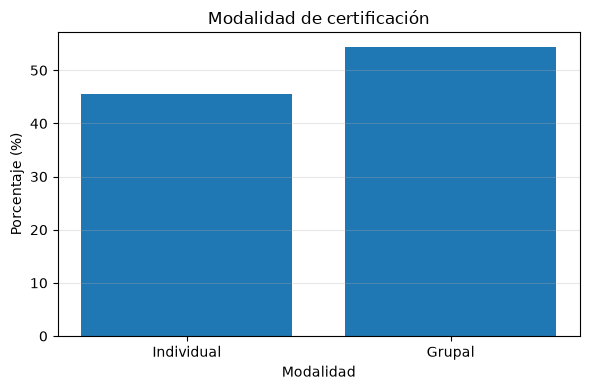

In [42]:
# Distribución de modalidades de certificación
plt.figure(figsize=(6, 4))

plt.bar(tabla_certificacion.index, tabla_certificacion["Porcentaje"])

plt.title("Modalidad de certificación")
plt.xlabel("Modalidad")
plt.ylabel("Porcentaje (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Comprobaciones finales

Verificamos que los datos originales no hayan cambiado, que los conteos y también porcentajes de los análisis sean coherentes.

In [43]:
# Comprobar que los datos originales no cambiaron
datos_originales = pd.read_parquet("../data/raw/2025/14_CAP600.parquet")

print("Datos originales sin cambios:", df_inocuidad.equals(datos_originales))

# Comprobar las respuestas válidas de la sección 7.1
print("Denominadores de 7.1:", (
    resumen_inocuidad["si"] + resumen_inocuidad["no"] == resumen_inocuidad["validas"]
).all())

# Comprobar los totales de las tablas territoriales
print("Totales de 7.2:", tabla_region["Total válido"].sum() == len(datos_region))
print("Totales de 7.3:", tabla_departamento["Total válido"].sum() == len(datos_region))

# Comprobar el cruce de información y conocimiento
print("Totales de 7.4:", tabla_conocimiento["Total válido"].sum() == len(datos_conocimiento))

# Comprobar las modalidades de certificación
print("Totales de 7.5:", tabla_certificacion["Frecuencia"].sum() == len(modalidades))

Datos originales sin cambios: True
Denominadores de 7.1: True
Totales de 7.2: True
Totales de 7.3: True
Totales de 7.4: True
Totales de 7.5: True


In [44]:
# Comprobar que los porcentajes estén entre 0 y 100
print("Porcentajes de 7.1:", resumen_inocuidad["porcentaje_si"].dropna().between(0, 100).all())

print("Porcentajes de 7.2:", tabla_region["Porcentaje Sí"].dropna().between(0, 100).all())

print("Porcentajes de 7.3:", tabla_departamento["Porcentaje Sí"].dropna().between(0, 100).all())

print("Porcentajes de 7.4:", tabla_conocimiento["Porcentaje Sí"].dropna().between(0, 100).all())

print("Porcentajes de 7.5:", tabla_certificacion["Porcentaje"].dropna().between(0, 100).all())

Porcentajes de 7.1: True
Porcentajes de 7.2: True
Porcentajes de 7.3: True
Porcentajes de 7.4: True
Porcentajes de 7.5: True


In [45]:
# Comprobar la distribución de modalidades de certificación
if len(modalidades) > 0:
    total_porcentaje = tabla_certificacion["Porcentaje"].sum()

    print("Suma de porcentajes:", total_porcentaje)
    print("Suma aproximadamente 100 %:", abs(total_porcentaje - 100) <= 0.02)
else:
    print("No hay modalidades válidas para calcular porcentajes.")

Suma de porcentajes: 100.0
Suma aproximadamente 100 %: True


Las comprobaciones permiten revisar la conservación de los datos originales, la consistencia de los denominadores y los rangos de los % calculados.